In [1]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
import scipy.sparse as sp
import anndata as ad
import gseapy as gp
from copy import deepcopy
import scanpy.external as sce
import pickle
from scipy import sparse


# sc.logging.print_version()
sc.settings.verbosity = 3
sc.set_figure_params(figsize=(5,5))

import sys
from pathlib import Path

_start = Path.cwd().resolve()
_repo_root = next((p for p in [_start, *_start.parents] if (p / "chronopack").exists()), _start)
if str(_repo_root) not in sys.path:
    sys.path.insert(0, str(_repo_root))

from chronopack.tradeseq import (
    ComputeSmoothCorrelations,
    TemporalPseudobulkFromAnnData,
    WriteTradeSeqInputsFromAnnData,
    load_negative_control_logcpm,
    smooth_series,
)
from chronopack.preprocessing import filter_technical_genes


In [2]:
# using CPM @ 1e6 scale factor
adata_hvg = sc.read_h5ad('../output/adata_hvg.h5ad')
adata = sc.read_h5ad('../output/adata_full.h5ad')

# Prepare input files for TradeSeq

In [6]:
mtx_agg, cpm_ref, logcpm_ref = load_negative_control_logcpm('../../thp1-k562-lps.hg38.rep/intmd/k562_neg-ctrl_mtx-agg.pkl')


In [7]:
cpm, logcpm = TemporalPseudobulkFromAnnData(adata)


In [14]:
shared_genes = list(set(adata.var.index) & set(logcpm_ref.columns))

cpm_ref = cpm_ref.loc[:, shared_genes]
logcpm_ref = logcpm_ref.loc[:, shared_genes]

cpm = cpm.loc[:, shared_genes]
logcpm = logcpm.loc[:, shared_genes]

adata.shape

(4034, 18833)

                 pearson_r_smooth  pearson_r_residual  pearson_r_diff  \
gene                                                                    
ENSG00000279881          1.000000            1.000000        1.000000   
PTCHD1                   1.000000            1.000000        1.000000   
ENSG00000300630          1.000000            1.000000        1.000000   
TM4SF1                   1.000000            1.000000        1.000000   
NPR3                     1.000000            1.000000        1.000000   
LINC03060                1.000000            1.000000        1.000000   
LINC03031                1.000000            1.000000        1.000000   
GSCAR                    1.000000            1.000000        1.000000   
DDX25                    1.000000            1.000000        1.000000   
ENSG00000225616          1.000000            1.000000        1.000000   
SAMD12                   1.000000            1.000000        1.000000   
ENSG00000302785          0.999997            0.9999

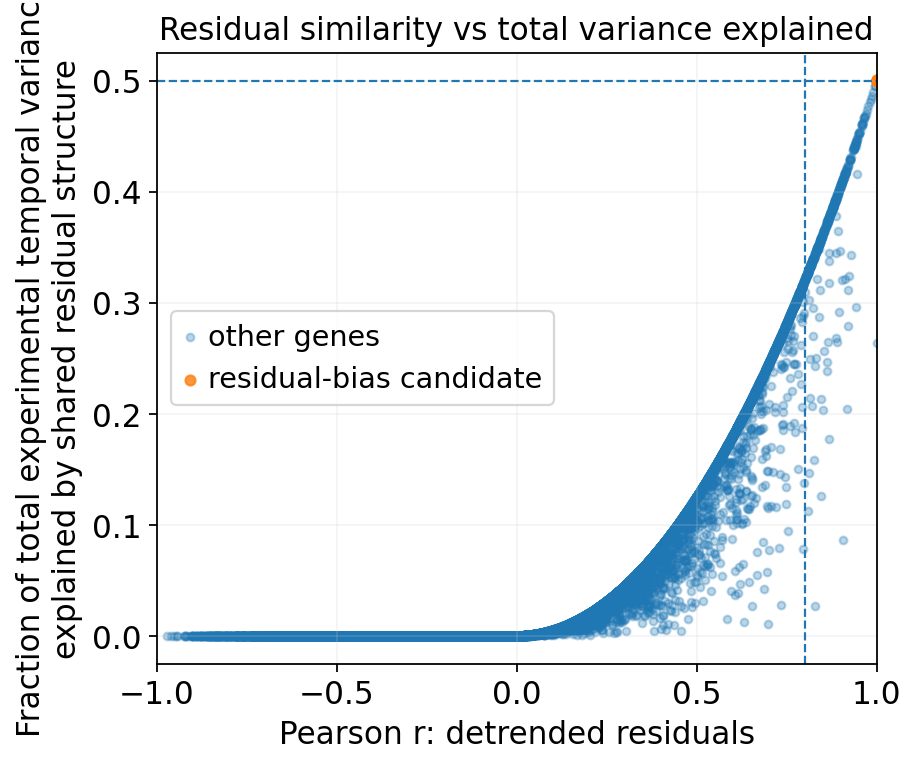

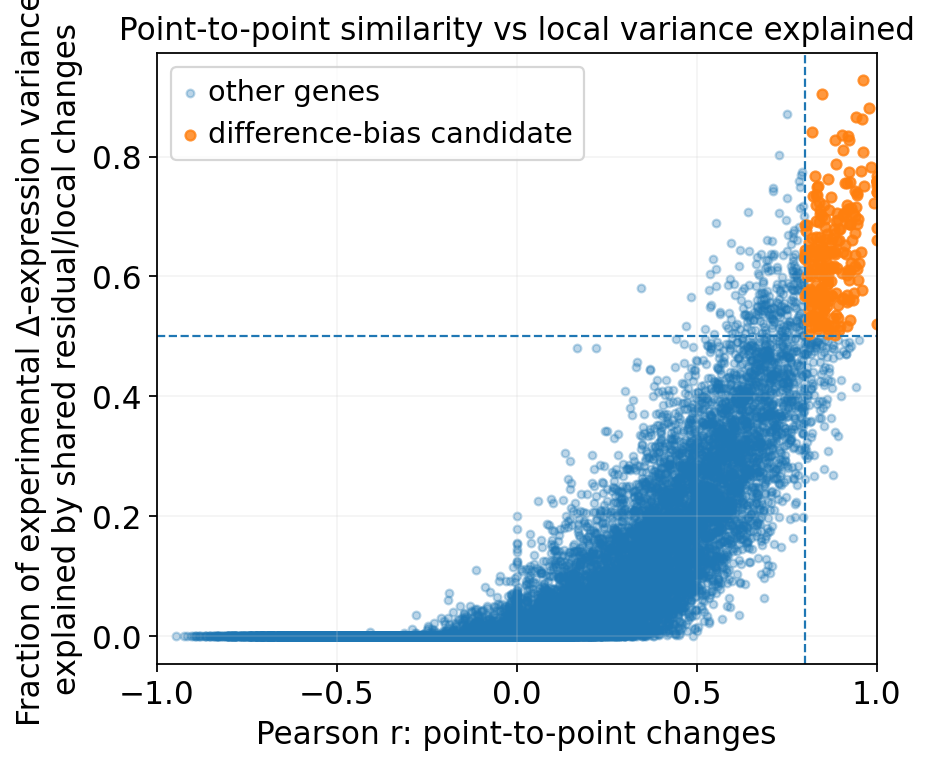

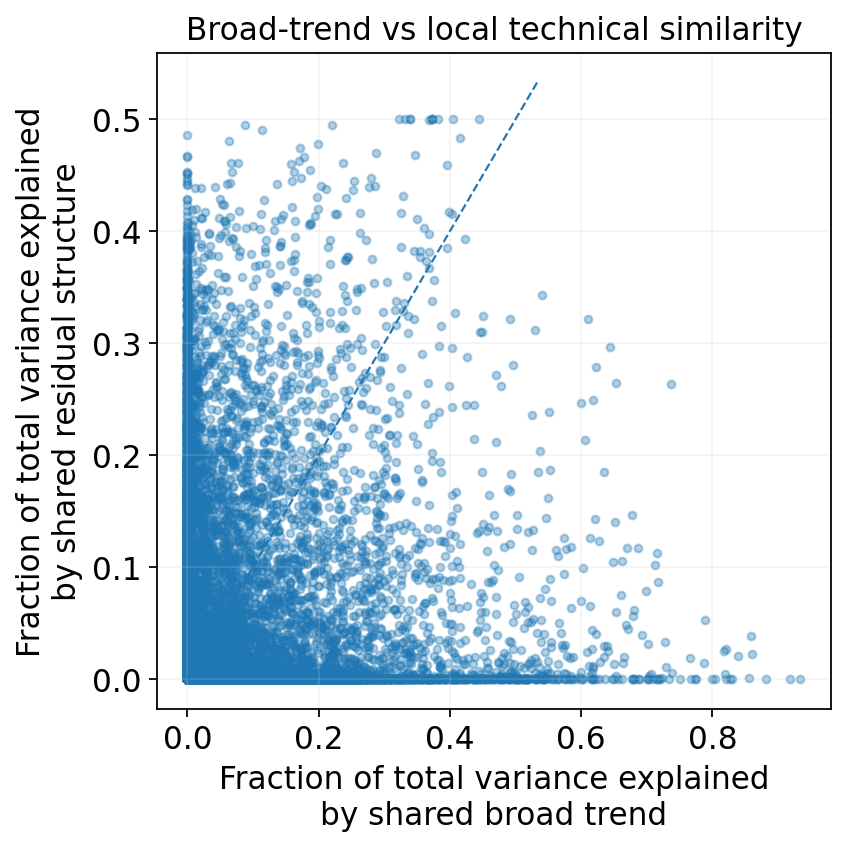

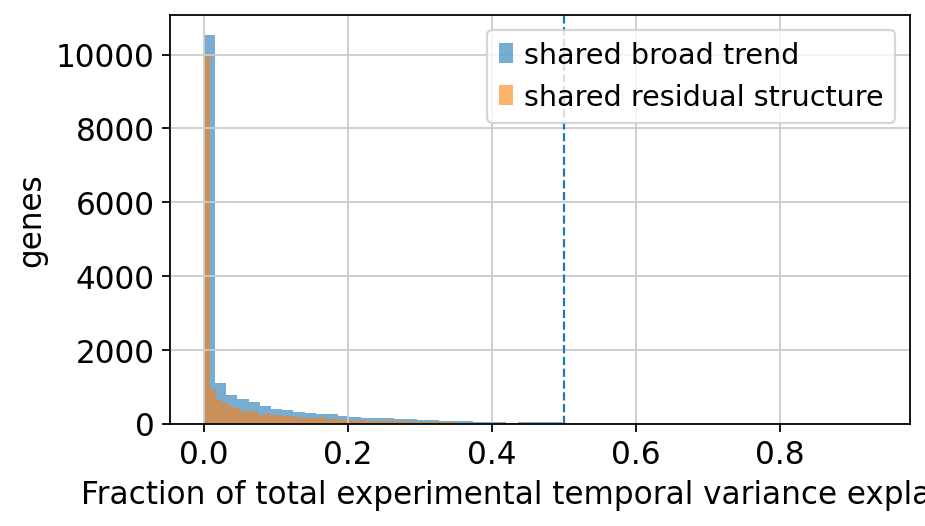

In [15]:
corr = ComputeSmoothCorrelations(
    logcpm,
    logcpm_ref,
    method='spline',
    method_kwargs=dict(s=None, k=3),
    local_r_threshold=0.8,
    local_fraction_threshold=0.5,
)


In [16]:
# Post hoc re-filter corr without recomputing trajectories

local_r_threshold = 0.7
local_fraction_threshold = 0.25

corr["tag_bias_candidate_residual"] = ((corr["pearson_r_residual"] >= local_r_threshold) & (corr["residual_explained_total_fraction"] >= local_fraction_threshold))
corr["tag_bias_candidate_diff"] = ((corr["pearson_r_diff"] >= local_r_threshold) & (corr["diff_residual_explained_fraction"] >= local_fraction_threshold))
# corr["tag_bias_candidate"] = (corr["tag_bias_candidate_residual"] | corr["tag_bias_candidate_diff"])
corr["tag_bias_candidate"] = corr["tag_bias_candidate_residual"]


# Optional: continuous score + re-sort
corr["tag_bias_score"] = corr[["residual_explained_total_fraction", "diff_residual_explained_fraction",]].max(axis=1, skipna=True)
corr = corr.sort_values("max_r_local", ascending=False,)

print("Tag-bias candidates:", int(corr["tag_bias_candidate"].sum()))

corr[
    [
        "pearson_r_residual",
        "residual_explained_total_fraction",
        "pearson_r_diff",
        "diff_residual_explained_fraction",
        "tag_bias_candidate_residual",
        "tag_bias_candidate_diff",
        "tag_bias_candidate",
    ]
].head(20)

Tag-bias candidates: 816


,pearson_r_residual,residual_explained_total_fraction,pearson_r_diff,diff_residual_explained_fraction,tag_bias_candidate_residual,tag_bias_candidate_diff,tag_bias_candidate
gene,,,,,,,
ENSG00000225616,1.000000,0.500292,1.000000,0.759610,True,True,True
SAMD12,1.000000,0.499928,1.000000,0.741651,True,True,True
LINC03060,1.000000,0.499872,1.000000,0.681521,True,True,True
ENSG00000279881,1.000000,0.500097,1.000000,0.755222,True,True,True
GSCAR,1.000000,0.263736,1.000000,0.521177,True,True,True
ENSG00000300630,1.000000,0.499547,1.000000,0.751198,True,True,True
PTCHD1,1.000000,0.500292,1.000000,0.759610,True,True,True
NPR3,1.000000,0.499928,1.000000,0.741651,True,True,True
TM4SF1,1.000000,0.500292,1.000000,0.759610,True,True,True


In [18]:
excl_genes = set(corr[corr['tag_bias_candidate'] == True].index.tolist())

In [26]:
'HSPA1B' in excl_genes

False

In [30]:
adata_hvg = adata.copy()
adata_hvg

AnnData object with n_obs × n_vars = 4034 × 18833
    obs: 'COUNTS', 'sample', 'time', 'time_group', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb', 'n_counts', 'n_genes', 'doublet_score', 'predicted_doublet', 'S_score', 'G2M_score', 'phase', 'p_terminal_for_selected_cell', 'selected_cell_marker', 'traj_leiden_sr', 'fate_p0_traj_last', 'fate_p1_traj_last', 'fate_hard_traj_last_argmax', 'fate_entropy_traj_last', 'fate_maxprob_traj_last', 'ret_to_own_cluster', 'ret_to_other_cluster'
    var: 'mt', 'rb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection'
    uns: 'cluster_ret_base_by_step', 'fate_hard_traj_last_argmax_colors', 'hvg', 'log1p', 'neighbors', 'ot_graph', 'pca', 'phase_colors', 'sample_colors', 'scrublet', 'terminal_cell_dist_idx_last', 'time_colors', 'time_gro

In [31]:
adata_hvg = adata.copy()
adata_hvg = filter_technical_genes(adata_hvg, exclude_genes=excl_genes)
adata_hvg


View of AnnData object with n_obs × n_vars = 4034 × 13905
    obs: 'COUNTS', 'sample', 'time', 'time_group', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb', 'n_counts', 'n_genes', 'doublet_score', 'predicted_doublet', 'S_score', 'G2M_score', 'phase', 'p_terminal_for_selected_cell', 'selected_cell_marker', 'traj_leiden_sr', 'fate_p0_traj_last', 'fate_p1_traj_last', 'fate_hard_traj_last_argmax', 'fate_entropy_traj_last', 'fate_maxprob_traj_last', 'ret_to_own_cluster', 'ret_to_other_cluster'
    var: 'mt', 'rb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection'
    uns: 'cluster_ret_base_by_step', 'fate_hard_traj_last_argmax_colors', 'hvg', 'log1p', 'neighbors', 'ot_graph', 'pca', 'phase_colors', 'sample_colors', 'scrublet', 'terminal_cell_dist_idx_last', 'time_colors', '

In [32]:
print('PLAU' in set(adata_hvg.var.index)) # similar shape
print('CD83' in set(adata_hvg.var.index)) # similar shape
print('EGR1' in set(adata_hvg.var.index)) # similar shape
print('IER3' in set(adata_hvg.var.index)) # similar shape

True
True
True
True


In [33]:
# TPs
print('REL' in set(adata_hvg.var.index)) # real, should be included
print('ALAS1' in set(adata_hvg.var.index)) # also real, should be included
print('SLC40A1' in set(adata_hvg.var.index)) # similar shape but a lot noisier
print('TRAF3' in set(adata_hvg.var.index)) # similar shape

# TNs
print('FTH1' in set(adata_hvg.var.index)) # should have high correlation
print('RELA' in set(adata_hvg.var.index)) # similar shape

True
True
True
True
True
True


In [34]:
adata_hvg.var["total_counts"] = np.asarray(
    adata_hvg.layers["counts"].sum(axis=0)
).ravel()

pd.Series(adata_hvg.var.index[adata_hvg.var['total_counts'] < 10]).to_csv('exclude_low-count-genes.k562.csv', index=False)
adata_hvg.var.index[adata_hvg.var['total_counts'] < 10]

/new-stg/home/alex/.tmp/ipykernel_1265423/2549053378.py:1: ImplicitModificationWarning: Trying to modify attribute `.var` of view, initializing view as actual.
  adata_hvg.var["total_counts"] = np.asarray(


Index(['AASS', 'ABCA2', 'ABCC6', 'ABCF2P1', 'ABHD15', 'ABRAXAS1P2', 'ACACB',
       'ACBD3-AS1', 'ACP3', 'ACSF2',
       ...
       'ZFHX2', 'ZFP92', 'ZNF134', 'ZNF252P-AS1', 'ZNF341-AS1', 'ZNF491',
       'ZNF556', 'ZNF772', 'ZNF888-AS1', 'ZSCAN22'],
      dtype='object', length=2393)

In [35]:
pd.Series(list(excl_genes)).to_csv('exclude_time-tag-bias_genes.csv', index=False, )
len(list(excl_genes))

In [42]:
adata_hvg.write_h5ad('../output/adata_prefiltered.1e4-variant.fixed.h5ad')
adata_full = adata.copy()

In [44]:
WriteTradeSeqInputsFromAnnData(adata_hvg, 'sc-K562-1e6-to-tradeSeq.fixed')
WriteTradeSeqInputsFromAnnData(adata, 'sc-K562-1e6-to-tradeSeq.fixed', tag='full')

(13905, 4034) (4034, 2)
Wrote subset_genes.csv and cell_libsize_full.csv
(18833, 4034) (4034, 2)
Wrote subset_genes.csv and cell_libsize_full.csv
